### Checking the Python Environment

This code checks which Python environment is running my notebook and confirms that the notebook is working correctly.

In [6]:
# Import sys to check which Python environment the notebook is using
import sys

# Display the location of the Python environment
print(sys.executable)

# Confirm that the notebook is working correctly
print("My notebook is working correctly!")

c:\Users\yetun\Desktop\Code Institute Registration Documents for Level 3 Data Analysis with AI\UNIT 3 ASSESSMENT FINAL PROJECT\.venv\Scripts\python.exe
My notebook is working correctly!


# Waste Collection Data Analysis: England 2024–2025

## 1. Introduction

Waste management is important for protecting the environment and keeping communities clean. Analysing waste collection data can help us understand waste patterns and identify areas that may need improvement.

In this project, I will analyse waste collection data for England for 2024–2025. I will use Python to explore the dataset, check its quality, identify useful patterns and present my findings using charts and visualisations.

## 2. Project Objectives

The main aim of this project is to analyse waste collection data for England for 2024–2025 and communicate useful findings.

My objectives are to:

- Understand the structure and contents of the dataset.
- Check the data for missing values, duplicates and errors.
- Clean and prepare the data where necessary.
- Explore waste collection patterns and differences using the available data.
- Create suitable charts to present important findings.
- Explain the results in simple English.
- Provide recommendations based on the findings and acknowledge the limitations of the analysis.

## 3. Dataset and Data Source

### Dataset Description

The dataset I will use for this project is called *Waste Collection Data England 2024–25*. It contains information about waste collection and processing reported by local authorities in England.

The dataset will help me explore the types of waste recorded, the quantities of waste processed, the facilities involved and differences between local authorities.

### Data Source

- **Publisher:** Department for Environment, Food and Rural Affairs (Defra).
- **Website:** [UK Government Data Portal — WasteDataFlow](https://www.data.gov.uk/dataset/0e0c12d8-24f6-461f-b4bc-f6d6a5bf2de5/waste-data-flow).
- **Dataset period:** 2024–2025.
- **File format:** CSV.
- **Licence:** Open Government Licence (OGL).

### Data Suitability

This dataset is relevant to my project because it provides information that can be explored using Python to identify patterns in waste collection and processing. I will inspect the dataset to understand its structure, check its quality and determine which variables are suitable for analysis.

### Ethical and Privacy Considerations

I will use the data responsibly and follow the conditions of its licence. I will check for missing values, inconsistencies and potential limitations before drawing conclusions. I will also avoid presenting misleading comparisons and will explain the limitations of my findings.

## 4. Loading and Inspecting the Dataset

In this section, I will load the waste collection dataset into Python using Pandas. I will inspect the number of rows and columns, review the column names and view the first five rows to understand how the data is organised.

In [3]:

# Import the libraries needed to locate and load the dataset
from pathlib import Path
import pandas as pd

# Search for the CSV file in the project folder and its parent folder
file_name = "Waste+Collection+data+England+2024-25.csv"
search_folders = [Path.cwd(), Path.cwd().parent]
matching_files = []

for folder in search_folders:
    matching_files.extend(folder.rglob(file_name))

# Remove duplicate file paths from the search results
matching_files = list(dict.fromkeys(matching_files))

# Load the dataset if the file is found
if matching_files:
    file_path = matching_files[0]
    waste_df = pd.read_csv(file_path)

    # Display the file location
    print("Dataset loaded from:", file_path)

    # Display the number of rows and columns
    print("\nNumber of rows and columns:", waste_df.shape)

    # Display the column names
    print("\nColumn names:")
    print(waste_df.columns.tolist())

    # Display the first five rows
    print("\nFirst five rows:")
    display(waste_df.head())
else:
    print("CSV file not found. Please check the file name and folder location.")


Dataset loaded from: c:\Users\yetun\Desktop\Code Institute Registration Documents for Level 3 Data Analysis with AI\UNIT 3 ASSESSMENT FINAL PROJECT\Waste+Collection+data+England+2024-25.csv

Number of rows and columns: (95777, 15)

Column names:
['This file contains data (subject to change) for the selected authorities and periods only if returns have been completed.', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14']

First five rows:


C:\Users\yetun\AppData\Local\Temp\ipykernel_8972\4041797478.py:19: DtypeWarning: Columns (8: Unnamed: 8, 9: Unnamed: 9, 10: Unnamed: 10, 11: Unnamed: 11, 12: Unnamed: 12, 13: Unnamed: 13) have mixed types. Specify dtype option on import or set low_memory=False.
  waste_df = pd.read_csv(file_path)


,This file contains data (subject to change) for the selected authorities and periods only if returns have been completed.,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14
0,Authority,Period,QuestionNumber,QuText,CollateText,RowText,ColText,Data,RowOrder,ColOrder,RowIdent,ColIdent,CollateID,columngroup,MaterialGroup
1,Adur District Council,Apr 24 - Jun 24,Q001,Authority Data: Note this data is prefilled.,NaN,Population of Authority,NaN,64687,1,1,587,271,-1,NaN,NaN
2,Adur District Council,Apr 24 - Jun 24,Q001,Authority Data: Note this data is prefilled.,NaN,Area in Hectares,NaN,4293.882,2,1,588,271,-1,NaN,NaN
3,Adur District Council,Apr 24 - Jun 24,Q001,Authority Data: Note this data is prefilled.,NaN,Population Density of Authority,NaN,15.065,3,1,589,271,-1,NaN,NaN
4,Adur District Council,Apr 24 - Jun 24,Q002,Authority Data: Note this data is prefilled.,NaN,Number of Households,NaN,26000,1,1,590,334,-1,NaN,NaN


## 5. Preparing the Dataset Structure

When I first loaded the dataset, I noticed that the first row contained a descriptive statement rather than the actual column headings. The real column headings appeared in the second row.

I will reload the dataset using the correct header row so that Python can identify the columns properly. This will make the dataset easier to inspect and analyse.

In [4]:

# Reload the CSV file using the second row as the column headings
waste_df = pd.read_csv(file_path, header=1)

# Remove any accidental spaces from the column names
waste_df.columns = waste_df.columns.str.strip()

# Display the dataset dimensions
print("Number of rows and columns:", waste_df.shape)

# Display the corrected column names
print("\nCorrect column names:")
print(waste_df.columns.tolist())

# Display the first five records
print("\nFirst five records:")
display(waste_df.head())


Number of rows and columns: (95776, 15)

Correct column names:
['Authority', 'Period', 'QuestionNumber', 'QuText', 'CollateText', 'RowText', 'ColText', 'Data', 'RowOrder', 'ColOrder', 'RowIdent', 'ColIdent', 'CollateID', 'columngroup', 'MaterialGroup']

First five records:


,Authority,Period,QuestionNumber,QuText,CollateText,RowText,ColText,Data,RowOrder,ColOrder,RowIdent,ColIdent,CollateID,columngroup,MaterialGroup
0,Adur District Council,Apr 24 - Jun 24,Q001,Authority Data: Note this data is prefilled.,NaN,Population of Authority,NaN,64687,1.0,1,587,271,-1,NaN,NaN
1,Adur District Council,Apr 24 - Jun 24,Q001,Authority Data: Note this data is prefilled.,NaN,Area in Hectares,NaN,4293.882,2.0,1,588,271,-1,NaN,NaN
2,Adur District Council,Apr 24 - Jun 24,Q001,Authority Data: Note this data is prefilled.,NaN,Population Density of Authority,NaN,15.065,3.0,1,589,271,-1,NaN,NaN
3,Adur District Council,Apr 24 - Jun 24,Q002,Authority Data: Note this data is prefilled.,NaN,Number of Households,NaN,26000,1.0,1,590,334,-1,NaN,NaN
4,Adur District Council,Apr 24 - Jun 24,Q002,Authority Data: Note this data is prefilled.,NaN,Dwelling Stock,NaN,28980,2.0,1,591,334,-1,NaN,NaN


## 6. Initial Data Quality Assessment

In this section, I will examine the structure and quality of the dataset before making any changes. I will check the number of rows and columns, identify data types, count missing values and check for duplicate records. These checks will help me decide what data preparation is needed.

In [7]:
# Display the number of rows and columns
print("Dataset dimensions:", waste_df.shape)

# Display the dataset structure and data types
print("\nDataset information:")
waste_df.info()

# Count missing values in each column
print("\nMissing values by column:")
print(waste_df.isnull().sum())

# Count duplicate rows
print("\nNumber of duplicate rows:", waste_df.duplicated().sum())

# Count unique local authorities and reporting periods
print("\nNumber of unique authorities:", waste_df["Authority"].nunique())
print("Number of unique reporting periods:", waste_df["Period"].nunique())

Dataset dimensions: (95776, 15)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 95776 entries, 0 to 95775
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Authority       95776 non-null  str    
 1   Period          95776 non-null  str    
 2   QuestionNumber  95776 non-null  str    
 3   QuText          95776 non-null  str    
 4   CollateText     16871 non-null  str    
 5   RowText         95410 non-null  str    
 6   ColText         83292 non-null  str    
 7   Data            95776 non-null  str    
 8   RowOrder        95410 non-null  float64
 9   ColOrder        95776 non-null  int64  
 10  RowIdent        95776 non-null  int64  
 11  ColIdent        95776 non-null  int64  
 12  CollateID       95776 non-null  int64  
 13  columngroup     0 non-null      float64
 14  MaterialGroup   56767 non-null  str    
dtypes: float64(2), int64(4), str(9)
memory usage: 11.0 MB

Missing values by colum

### Initial Data Quality Findings

My initial checks show that the dataset contains 95,776 records and 15 columns, covering 321 local authorities and four reporting periods.

I found no exact duplicate rows. However, several columns contain missing values, and the `Data` column is currently stored as text rather than a numeric data type. The `columngroup` column contains only missing values.

Before cleaning the dataset, I will investigate the missing values, inspect the reporting periods and examine the values in the `Data` column. This will help me decide which columns and records are suitable for analysis.

In [8]:
# Display the unique reporting periods
print("Reporting periods:")
print(waste_df["Period"].unique())

# Display examples of values in the Data column
print("\nExamples of values in the Data column:")
print(waste_df["Data"].drop_duplicates().head(20).tolist())

# Count values in the Data column that cannot be converted to numbers
numeric_data = pd.to_numeric(waste_df["Data"], errors="coerce")
non_numeric_count = numeric_data.isna().sum()

print("\nValues that cannot be converted to numbers:", non_numeric_count)

# Display the first five rows with their key descriptive columns
print("\nSample records for further inspection:")
display(waste_df[["Authority", "Period", "QuestionNumber", "RowText", "Data"]].head())

Reporting periods:
<StringArray>
['Apr 24 - Jun 24', 'Jul 24 - Sep 24', 'Oct 24 - Dec 24', 'Jan 25 - Mar 25']
Length: 4, dtype: str

Examples of values in the Data column:
['64687', '4293.882', '15.065', '26000', '28980', '17.594', '68', '1', '1160.23', '6820', 'No', '6.21', '29133', '5', '0.28', '1055.76', 'Yes', '7.57', '5.37', '51.36']

Values that cannot be converted to numbers: 12594

Sample records for further inspection:


,Authority,Period,QuestionNumber,RowText,Data
0,Adur District Council,Apr 24 - Jun 24,Q001,Population of Authority,64687
1,Adur District Council,Apr 24 - Jun 24,Q001,Area in Hectares,4293.882
2,Adur District Council,Apr 24 - Jun 24,Q001,Population Density of Authority,15.065
3,Adur District Council,Apr 24 - Jun 24,Q002,Number of Households,26000
4,Adur District Council,Apr 24 - Jun 24,Q002,Dwelling Stock,28980


In [9]:
# Convert Data values to numeric where possible for investigation
numeric_data = pd.to_numeric(waste_df["Data"], errors="coerce")

# Select values that could not be converted to numbers
non_numeric_values = waste_df.loc[numeric_data.isna(), "Data"]

# Display the most common non-numeric values
print("Most common non-numeric values:")
print(non_numeric_values.value_counts().head(20))

# Display the number of different non-numeric values
print("\nNumber of unique non-numeric values:")
print(non_numeric_values.nunique())

# Display example records containing non-numeric values
print("\nExample records with non-numeric values:")
display(
    waste_df.loc[
        numeric_data.isna(),
        ["Authority", "Period", "QuestionNumber", "RowText", "Data"]
    ].head(10)
)

Most common non-numeric values:
Data
No                                         4619
Yes                                        2271
Fortnightly                                1617
Incinerated with Energy Recovery           1591
Weekly                                      568
Non Hazardous Landfill                      459
Other                                       337
Residual Waste MRF                          257
MBT                                         197
Inert Landfill                              145
Hazardous Landfill                          127
Incinerated without Energy Recovery         104
Advanced Thermal Treatment                   38
Monthly                                      36
More frequently than Weekly                  31
Less frequently than Monthly                 12
Fenland District Council                      1
Huntingdonshire District Council              1
East Cambridgeshire District Council          1
Cambridge City and South Cambs Councils       1
Nam

,Authority,Period,QuestionNumber,RowText,Data
10,Adur District Council,Apr 24 - Jun 24,Q010,Green garden waste only,No
13,Adur District Council,Apr 24 - Jun 24,Q010,WEEE - Small Domestic App,No
16,Adur District Council,Apr 24 - Jun 24,Q010,WEEE - Fridges & Freezers,No
19,Adur District Council,Apr 24 - Jun 24,Q010,Gas bottles,No
22,Adur District Council,Apr 24 - Jun 24,Q010,Co mingled materials,Yes
25,Adur District Council,Apr 24 - Jun 24,Q010,Other Scrap metal,No
27,Adur District Council,Apr 24 - Jun 24,Q011,Waste food only,No
29,Adur District Council,Apr 24 - Jun 24,Q011,Card,No
31,Adur District Council,Apr 24 - Jun 24,Q011,Co mingled materials,No
61,Adur District Council,Jul 24 - Sep 24,Q010,Green garden waste only,No


### Investigation of Non-Numeric Values

My investigation found that the `Data` column contains both numeric and non-numeric values. The non-numeric values include Yes/No responses, waste collection frequencies, waste treatment methods and disposal categories.

I identified 12,594 values that could not be converted to numbers, with 201 unique non-numeric values. These values are not necessarily errors because they may represent valid responses or categories in the original dataset.

I will preserve these values while investigating the dataset further. I will only convert values to numeric where appropriate for the specific analysis, rather than changing the entire column.

In [10]:
# Count the number of records for each question
print("Number of records by question:")
print(waste_df["QuestionNumber"].value_counts().head(20))

# Display the different question descriptions
print("\nQuestion descriptions:")
question_descriptions = waste_df[
    ["QuestionNumber", "QuText"]
].drop_duplicates()

display(question_descriptions.head(20))

# Count the different row descriptions
print("\nMost common row descriptions:")
print(waste_df["RowText"].value_counts().head(20))

Number of records by question:
QuestionNumber
Q010     18384
Q023     17399
Q014     16871
Q016     11442
Q002      6268
Q011      3885
Q001      3788
Q017      3509
Q005      3229
Q004      1870
Q006      1646
Q025      1238
Q024      1156
Q018      1019
Q012      1000
Q033       966
Q026       814
Q013       366
Q007       322
Q015a      250
Name: count, dtype: int64

Question descriptions:


,QuestionNumber,QuText
0,Q001,Authority Data: Note this data is prefilled.
3,Q002,Authority Data: Note this data is prefilled.
8,Q010,Tonnes of material collected through kerbside ...
26,Q011,"Tonnes of material collected from commercial,..."
32,Q017,Tonnes of material collected at bring sites op...
33,Q023,Please provide details of other waste collecte...
47,Q024,How many reported fly-tipping incidents were t...
48,Q025,How many abandoned vehicles were disposed of b...
49,Q026,How many fridges/freezers were disposed of by ...
50,Q034,Tonnes of material collected for recycling at ...



Most common row descriptions:
RowText
Co mingled materials                                       4770
Green garden waste only                                    4384
Textiles & footwear                                        3166
WEEE - Fridges & Freezers                                  3036
WEEE - Small Domestic App                                  2637
Collected household waste : Regular Collection             2451
Mixed glass                                                2429
Collected household waste : Street Cleaning                2377
Waste Arising from clearance of fly-tipped materials       2331
WEEE - TVs & Monitors                                      2252
Collected household waste : Bulky Waste                    2010
WEEE - Large Domestic App                                  2005
Other Scrap metal                                          1912
Mixed paper &  card                                        1851
Collected non-household waste : Commercial & Industrial    1722
W

In [11]:
# Get the unique question codes and their full descriptions
question_descriptions = (
    waste_df[["QuestionNumber", "QuText"]]
    .drop_duplicates()
    .sort_values("QuestionNumber")
)

# Display the full question descriptions without truncation
for _, row in question_descriptions.iterrows():
    print(f"{row['QuestionNumber']}: {row['QuText']}")
    print("-" * 80)

Q001: Authority Data:  Note this data is prefilled.
--------------------------------------------------------------------------------
Q002: Authority Data:  Note this data is prefilled.
--------------------------------------------------------------------------------
Q004: How many households were provided with the following methods of residual waste containment?
--------------------------------------------------------------------------------
Q005: How many households were offered the following containment methods for dry recyclable collection?
--------------------------------------------------------------------------------
Q006: How many households were offered  the following containment methods for green waste / organics collection?
--------------------------------------------------------------------------------
Q007: How many households are served by a kerbside collection of :
--------------------------------------------------------------------------------
Q010: Tonnes of material col

### Understanding the Dataset and Selecting an Analysis Focus

The dataset contains information about household and non-household waste collection, recycling, waste disposal and local authority services. It covers four quarterly reporting periods from April 2024 to March 2025.

Based on the available question descriptions, I will initially investigate waste collection and recycling patterns across local authorities and reporting periods. I will examine the relevant records before confirming the final analysis focus and will use the available data to guide my decisions.

In [14]:
# Select records relating to household kerbside waste collection
kerbside_df = waste_df[waste_df["QuestionNumber"] == "Q010"].copy()

# Display the number of records for this question
print("Q010 records:", kerbside_df.shape[0])

# Inspect the waste categories recorded in RowText
print("\nWaste categories:")
print(kerbside_df["RowText"].dropna().unique()[:20])

# Inspect the column descriptions
print("\nColumn descriptions:")
print(kerbside_df["ColText"].dropna().unique()[:20])

# Display sample records with their key details
print("\nSample Q010 records:")
display(
    kerbside_df[
        ["Authority", "Period", "RowText", "ColText", "Data", "MaterialGroup"]
    ].head(10)
)

Q010 records: 18384

Waste categories:
<StringArray>
[                       'Green garden waste only',
                      'WEEE - Small Domestic App',
                      'WEEE - Fridges & Freezers',
                                    'Gas bottles',
                           'Co mingled materials',
                              'Other Scrap metal',
                      'WEEE - Large Domestic App',
                                    'Mixed glass',
                                'Waste food only',
                                    'Mixed tyres',
                                     'Mattresses',
                                           'Wood',
 'WEEE - Flourescent tubes and other light bulbs',
                          'WEEE - TVs & Monitors',
                            'Mixed paper &  card',
                                      'Furniture',
                                        'PET [1]',
                                       'HDPE [2]',
                             

,Authority,Period,RowText,ColText,Data,MaterialGroup
8,Adur District Council,Apr 24 - Jun 24,Green garden waste only,Tonnage collected for recycling,1160.23,Organic
9,Adur District Council,Apr 24 - Jun 24,Green garden waste only,No. of households receiving a collection,6820,Organic
10,Adur District Council,Apr 24 - Jun 24,Green garden waste only,Collected Co-mingled?,No,Organic
11,Adur District Council,Apr 24 - Jun 24,WEEE - Small Domestic App,Tonnage collected for recycling,6.21,WEEE
12,Adur District Council,Apr 24 - Jun 24,WEEE - Small Domestic App,No. of households receiving a collection,29133,WEEE
13,Adur District Council,Apr 24 - Jun 24,WEEE - Small Domestic App,Collected Co-mingled?,No,WEEE
14,Adur District Council,Apr 24 - Jun 24,WEEE - Fridges & Freezers,Tonnage collected for recycling,5,WEEE
15,Adur District Council,Apr 24 - Jun 24,WEEE - Fridges & Freezers,No. of households receiving a collection,29133,WEEE
16,Adur District Council,Apr 24 - Jun 24,WEEE - Fridges & Freezers,Collected Co-mingled?,No,WEEE
17,Adur District Council,Apr 24 - Jun 24,Gas bottles,Tonnage collected for recycling,0.28,Metal


### Initial Investigation of Q010

I examined the records for Q010, which relates to material collected through household kerbside schemes. The question contains different waste categories and six types of measures, including recycling tonnage, household collection coverage, reuse tonnage and rejected materials.

This shows that the records contain different types of information. I will separate the measures before calculating totals or creating visualisations to avoid combining incompatible values.

In [15]:
# Count records for each measure in Q010
print("Number of records by measure:")
print(kerbside_df["ColText"].value_counts(dropna=False).to_string())

# Compare the recorded values for each measure
print("\nExamples of values by measure:")
for measure in kerbside_df["ColText"].dropna().unique():
    print(f"\n{measure}")
    print(
        kerbside_df.loc[
            kerbside_df["ColText"] == measure, "Data"
        ].head(5).tolist()
    )

Number of records by measure:
ColText
No. of households receiving a collection                          6518
Tonnage collected for recycling                                   6330
Collected Co-mingled?                                             4209
Tonnage collected for recycling but actually rejected/disposed     546
Tonnage Collected for Reuse                                        507
Tonnage Collected for reuse but actually rejected / disposed       274

Examples of values by measure:

Tonnage collected for recycling
['1160.23', '6.21', '5', '0.28', '1055.76']

No. of households receiving a collection
['6820', '29133', '29133', '29133', '29133']

Collected Co-mingled?
['No', 'No', 'No', 'No', 'Yes']

Tonnage collected for recycling but actually rejected/disposed
['0', '0', '0', '0', '0']

Tonnage Collected for Reuse
['0.05', '0.33', '0.22', '0.49', '2.79']

Tonnage Collected for reuse but actually rejected / disposed
['0', '0', '0', '0', '0']


### Understanding the Q010 Measures

My investigation identified six measures within Q010. These include recycling tonnage, household collection coverage, co-mingled collection, rejected recycling materials, reuse tonnage and rejected reuse materials.

The measures use different units and include both numeric and categorical values. I will keep these measures separate during analysis and only calculate totals or comparisons where the measurements are appropriate and meaningful.

In [16]:
# Check missing values in the Q010 dataset
print("Missing values in Q010:")
print(kerbside_df.isnull().sum().to_string())

# Check the number of records in each measure
print("\nRecords by measure:")
print(kerbside_df["ColText"].value_counts().to_string())

# Check whether any Data values are blank
print("\nBlank Data values:", kerbside_df["Data"].isna().sum())

# Check whether the Data column contains empty strings
print(
    "Empty Data strings:",
    kerbside_df["Data"].astype("string").str.strip().eq("").sum()
)

Missing values in Q010:
Authority             0
Period                0
QuestionNumber        0
QuText                0
CollateText       18384
RowText               0
ColText               0
Data                  0
RowOrder              0
ColOrder              0
RowIdent              0
ColIdent              0
CollateID             0
columngroup       18384
MaterialGroup         0

Records by measure:
ColText
No. of households receiving a collection                          6518
Tonnage collected for recycling                                   6330
Collected Co-mingled?                                             4209
Tonnage collected for recycling but actually rejected/disposed     546
Tonnage Collected for Reuse                                        507
Tonnage Collected for reuse but actually rejected / disposed       274

Blank Data values: 0
Empty Data strings: 0


### Preparing Q010 for Analysis

I checked the Q010 data and found no missing or blank values in the main columns.

The `Data` column contains numbers and text, such as Yes and No. I will prepare the data carefully by converting only the values that represent numbers. I will keep the text values unchanged and preserve the original dataset.

In [17]:
# Create a separate copy of Q010 for analysis
kerbside_clean = kerbside_df.copy()

# Identify measures that should contain numeric values
numeric_measures = [
    "Tonnage collected for recycling",
    "No. of households receiving a collection",
    "Tonnage collected for recycling but actually rejected/disposed",
    "Tonnage Collected for Reuse",
    "Tonnage Collected for reuse but actually rejected / disposed"
]

# Create a numeric analysis column without changing the original Data column
kerbside_clean["Data_numeric"] = pd.NA

# Convert values only for the numeric measures
numeric_mask = kerbside_clean["ColText"].isin(numeric_measures)

kerbside_clean.loc[numeric_mask, "Data_numeric"] = pd.to_numeric(
    kerbside_clean.loc[numeric_mask, "Data"],
    errors="coerce"
)

# Display a sample of the prepared data
display(
    kerbside_clean[
        ["Authority", "Period", "RowText", "ColText", "Data", "Data_numeric"]
    ].head(10)
)

# Check whether numeric measures converted successfully
print("Numeric measure records:", numeric_mask.sum())
print(
    "Numeric values successfully converted:",
    kerbside_clean.loc[numeric_mask, "Data_numeric"].notna().sum()
)

# Confirm that categorical responses are preserved
print("\nCo-mingled responses:")
print(kerbside_clean.loc[
    kerbside_clean["ColText"] == "Collected Co-mingled?", "Data"
].value_counts())

,Authority,Period,RowText,ColText,Data,Data_numeric
8,Adur District Council,Apr 24 - Jun 24,Green garden waste only,Tonnage collected for recycling,1160.23,1160.23
9,Adur District Council,Apr 24 - Jun 24,Green garden waste only,No. of households receiving a collection,6820,6820.0
10,Adur District Council,Apr 24 - Jun 24,Green garden waste only,Collected Co-mingled?,No,<NA>
11,Adur District Council,Apr 24 - Jun 24,WEEE - Small Domestic App,Tonnage collected for recycling,6.21,6.21
12,Adur District Council,Apr 24 - Jun 24,WEEE - Small Domestic App,No. of households receiving a collection,29133,29133.0
13,Adur District Council,Apr 24 - Jun 24,WEEE - Small Domestic App,Collected Co-mingled?,No,<NA>
14,Adur District Council,Apr 24 - Jun 24,WEEE - Fridges & Freezers,Tonnage collected for recycling,5,5.0
15,Adur District Council,Apr 24 - Jun 24,WEEE - Fridges & Freezers,No. of households receiving a collection,29133,29133.0
16,Adur District Council,Apr 24 - Jun 24,WEEE - Fridges & Freezers,Collected Co-mingled?,No,<NA>
17,Adur District Council,Apr 24 - Jun 24,Gas bottles,Tonnage collected for recycling,0.28,0.28


Numeric measure records: 14175
Numeric values successfully converted: 14175

Co-mingled responses:
Data
No     3113
Yes    1096
Name: count, dtype: int64


### Checking the Prepared Data

I successfully converted all 14,175 values from the numeric measures in Q010 into numbers. The Yes/No responses remained unchanged in the original `Data` column. I kept the original dataset and created a separate working copy for analysis.

This prepares the numeric values for further checks and analysis.

In [18]:
# Select records that contain numeric measures
numeric_records = kerbside_clean[
    kerbside_clean["Data_numeric"].notna()
]

# Show basic statistics for the numeric values
print("Summary of numeric values:")
display(numeric_records["Data_numeric"].describe())

# Count negative numeric values
print(
    "\nNumber of negative values:",
    (numeric_records["Data_numeric"] < 0).sum()
)

# Check for any missing values after conversion
print(
    "Missing numeric values:",
    numeric_records["Data_numeric"].isna().sum()
)

Summary of numeric values:


count     14175.0
unique     6763.0
top           0.0
freq       1089.0
Name: Data_numeric, dtype: float64


Number of negative values: 0
Missing numeric values: 0


In [19]:
# Check the data type of the prepared numeric column
print("Data type:", kerbside_clean["Data_numeric"].dtype)

# Display summary statistics for each numeric measure separately
for measure in numeric_measures:
    measure_data = kerbside_clean.loc[
        kerbside_clean["ColText"] == measure,
        "Data_numeric"
    ]

    print(f"\nSummary for: {measure}")
    display(measure_data.describe())

Data type: object

Summary for: Tonnage collected for recycling


count     6330.0
unique    5192.0
top          0.0
freq        39.0
Name: Data_numeric, dtype: float64


Summary for: No. of households receiving a collection


count      6518.0
unique     1422.0
top       86570.0
freq         51.0
Name: Data_numeric, dtype: float64


Summary for: Tonnage collected for recycling but actually rejected/disposed


count     546.0
unique     46.0
top         0.0
freq      501.0
Name: Data_numeric, dtype: float64


Summary for: Tonnage Collected for Reuse


count     507.0
unique    245.0
top         0.0
freq      244.0
Name: Data_numeric, dtype: float64


Summary for: Tonnage Collected for reuse but actually rejected / disposed


count     274.0
unique      1.0
top         0.0
freq      274.0
Name: Data_numeric, dtype: float64

In [20]:

# Convert the prepared values to a proper numeric data type
kerbside_clean["Data_numeric"] = pd.to_numeric(
    kerbside_clean["Data_numeric"],
    errors="coerce"
)

# Confirm the corrected data type
print("Data type:", kerbside_clean["Data_numeric"].dtype)

# Check summary statistics for recycling tonnage
recycling_tonnage = kerbside_clean.loc[
    kerbside_clean["ColText"] == "Tonnage collected for recycling",
    "Data_numeric"
]

print("\nSummary of recycling tonnage:")
display(recycling_tonnage.describe())

# Check for negative values in numeric measures
numeric_records = kerbside_clean[
    kerbside_clean["ColText"].isin(numeric_measures)
    & kerbside_clean["Data_numeric"].notna()
]

print(
    "\nNumber of negative values:",
    (numeric_records["Data_numeric"] < 0).sum()
)


Data type: float64

Summary of recycling tonnage:


count     6330.000000
mean      1137.660461
std       1680.805024
min          0.000000
25%          5.521250
50%        481.860000
75%       1680.310000
max      15541.480000
Name: Data_numeric, dtype: float64


Number of negative values: 0


### Findings from Numeric Data Preparation

I converted the `Data_numeric` column to the correct numeric data type, `float64`. The recycling tonnage measure contains 6,330 records, with an average value of 1,137.66 and a median of 481.86. The minimum value is zero, and the maximum is 15,541.48. I found no negative values in the numeric measures.

The average recycling tonnage is higher than the median, suggesting that some records have considerably higher values than others. These statistics describe individual records and should not be interpreted as England's total recycling tonnage. I will investigate the data further before drawing conclusions.

### Analysing Recycling Tonnage by Reporting Period

In this section, I will compare recycling tonnage across the four reporting periods from April 2024 to March 2025. I will calculate the total recorded tonnage for each period and use a bar chart to compare the results. This will help me see how the figures differ across the year.

In [21]:
# Filter records for recycling tonnage
recycling_df = kerbside_clean[
    kerbside_clean["ColText"] == "Tonnage collected for recycling"
].copy()

# Calculate total recorded recycling tonnage for each period
period_totals = recycling_df.groupby("Period")["Data_numeric"].sum()

# Display the results
print("Recorded recycling tonnage by reporting period:")
display(period_totals)

Recorded recycling tonnage by reporting period:


Period
Apr 24 - Jun 24    2120028.195
Jan 25 - Mar 25    1489171.234
Jul 24 - Sep 24    1950380.516
Oct 24 - Dec 24    1641810.773
Name: Data_numeric, dtype: float64

### Understanding the Results

The results show differences in recorded recycling tonnage across the four reporting periods. April to June 2024 had the highest recorded total, while January to March 2025 had the lowest. The recorded totals decreased across the reporting periods. I will use a bar chart to make these differences easier to see.

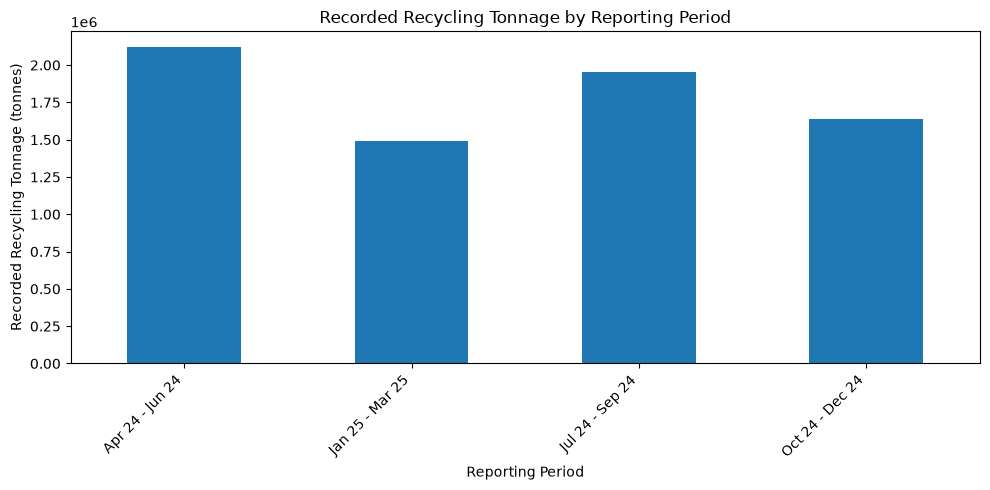

In [24]:

# Import Matplotlib for creating charts
import matplotlib.pyplot as plt

# Create a bar chart of recycling tonnage by reporting period
period_totals.plot(kind="bar", figsize=(10, 5))

# Add a chart title and axis labels
plt.title("Recorded Recycling Tonnage by Reporting Period")
plt.xlabel("Reporting Period")
plt.ylabel("Recorded Recycling Tonnage (tonnes)")

# Rotate the period labels to make them easier to read
plt.xticks(rotation=45, ha="right")

# Adjust the layout and display the chart
plt.tight_layout()
plt.show()


### Findings from the Bar Chart

The bar chart shows the recorded recycling tonnage for the four reporting periods. April to June 2024 had the highest recorded total, at approximately 2.12 million tonnes. January to March 2025 had the lowest, at approximately 1.49 million tonnes.

The results show that the recorded totals varied across the year. Further checks are needed before I can explain why these differences occurred.

### Analysing Recycling Tonnage by Local Authority

In this section, I will compare the recorded recycling tonnage across local authorities. This will help me identify authorities with higher and lower recorded totals. I will focus on the 10 authorities with the highest recorded recycling tonnage.

In [25]:

# Calculate recorded recycling tonnage for each local authority
authority_totals = (
    recycling_df.groupby("Authority")["Data_numeric"]
    .sum()
    .sort_values(ascending=False)
)

# Select the 10 authorities with the highest recorded totals
top_10_authorities = authority_totals.head(10)

# Display the results
print("Top 10 local authorities by recorded recycling tonnage:")
display(top_10_authorities)


Top 10 local authorities by recorded recycling tonnage:


Authority
Somerset Council                    91112.058
Buckinghamshire Council             90871.100
North Yorkshire Council             84590.898
Wiltshire                           74269.305
East Riding of Yorkshire Council    74250.080
Leeds City Council MBC              73767.320
Dorset Council                      73295.410
Cheshire East                       72902.580
Cornwall                            72728.390
West Northamptonshire               71660.750
Name: Data_numeric, dtype: float64

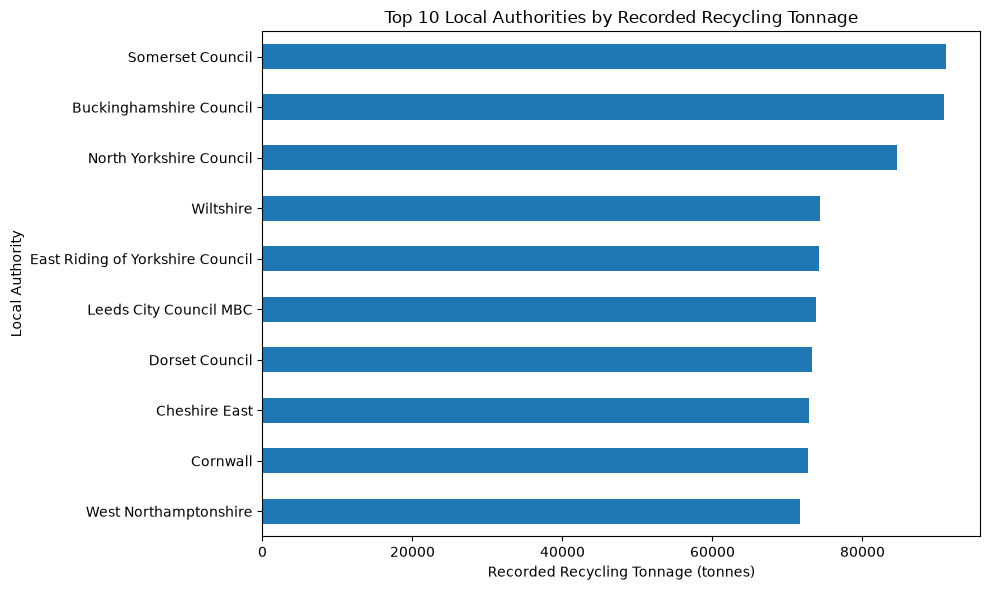

In [26]:

# Import Matplotlib for creating the chart
import matplotlib.pyplot as plt

# Create a bar chart of the top 10 local authorities
top_10_authorities.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

# Add the chart title and axis labels
plt.title("Top 10 Local Authorities by Recorded Recycling Tonnage")
plt.xlabel("Recorded Recycling Tonnage (tonnes)")
plt.ylabel("Local Authority")

# Adjust the layout and display the chart
plt.tight_layout()
plt.show()


### Findings from the Top 10 Local Authorities

Somerset Council had the highest recorded recycling tonnage, at about 91,112 tonnes. Buckinghamshire Council came second, with about 90,871 tonnes. West Northamptonshire had the lowest total among the top 10 authorities, at about 71,661 tonnes.

The results show that the recorded recycling tonnage was different across the authorities. However, a higher total does not always mean better recycling performance because authorities may have different populations and amounts of waste.

### Checking Data Coverage Across Local Authorities

In this section, I will check how many reporting periods are available for each local authority. This will help me understand whether the authorities can be compared fairly using the recorded recycling tonnage.

In [27]:

# Count the reporting periods recorded for each local authority
periods_per_authority = recycling_df.groupby("Authority")["Period"].nunique()

# Display the number of authorities with 1, 2, 3 or 4 reporting periods
print("Number of reporting periods available per authority:")
display(periods_per_authority.value_counts().sort_index())

# Show authorities that do not have all four reporting periods
incomplete_authorities = periods_per_authority[periods_per_authority < 4]

print("\nAuthorities with fewer than four reporting periods:")
display(incomplete_authorities)


Number of reporting periods available per authority:


Period
4    294
Name: count, dtype: int64


Authorities with fewer than four reporting periods:


Series([], Name: Period, dtype: int64)

### Findings from the Data Coverage Check

I found that all 294 local authorities in the recycling tonnage data have records for all four reporting periods. This means each of these authorities has data covering April 2024 to March 2025.

Having all four periods makes it easier to compare the recorded totals across the year. However, differences in population size and waste collected should still be considered when comparing authorities.

### Exploring Recycling Materials

In this section, I will look at the different materials recorded in the recycling data. I will count how many records there are for each material to see which materials appear most often. These counts will help me understand the data, but they do not show the amount of each material recycled.

In [28]:

# Count the records for each material in the recycling tonnage data
material_counts = recycling_df["RowText"].value_counts()

# Display the 10 materials with the most records
print("Top 10 materials by number of records:")
display(material_counts.head(10))


Top 10 materials by number of records:


RowText
Co mingled materials           1124
Green garden waste only        1004
WEEE - Fridges & Freezers       590
Waste food only                 507
Mixed paper &  card             340
WEEE - Small Domestic App       337
WEEE - TVs & Monitors           323
WEEE - Large Domestic App       286
Mixed glass                     280
Mixed garden and food waste     166
Name: count, dtype: int64

In [29]:

# Calculate recorded recycling tonnage for each material
material_tonnage = (
    recycling_df.groupby("RowText")["Data_numeric"]
    .sum()
    .sort_values(ascending=False)
)

# Display the 10 materials with the highest recorded tonnage
print("Top 10 materials by recorded recycling tonnage:")
display(material_tonnage.head(10))


Top 10 materials by recorded recycling tonnage:


RowText
Co mingled materials           3141130.412
Green garden waste only        2054716.165
Mixed garden and food waste     601773.796
Waste food only                 539624.906
Mixed paper &  card             409827.372
Mixed glass                     246495.249
Card                             91317.733
Paper                            37351.547
Plastics                         30429.142
Mixed Plastic Bottles             8020.125
Name: Data_numeric, dtype: float64

#### Comparing the Top Five Recycling Materials

In this section, I will compare the recorded recycling tonnage of the five materials with the highest totals. I will use a pie chart to show each material's share of their combined tonnage. This will help me compare the five materials.

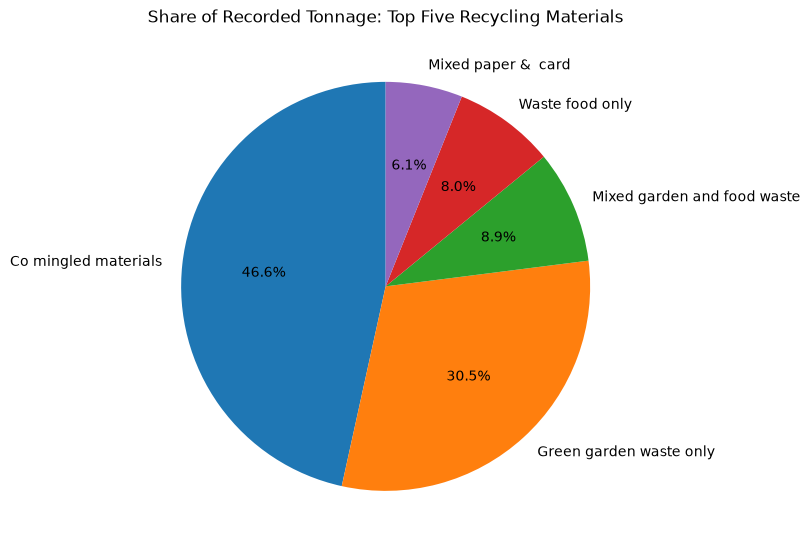

In [30]:

# Import Matplotlib for creating the pie chart
import matplotlib.pyplot as plt

# Select the five materials with the highest recorded tonnage
top_5_materials = material_tonnage.head(5)

# Create the pie chart
top_5_materials.plot(
    kind="pie",
    figsize=(8, 8),
    autopct="%1.1f%%",
    startangle=90
)

# Add a title and remove the default y-axis label
plt.title("Share of Recorded Tonnage: Top Five Recycling Materials")
plt.ylabel("")

# Display the chart
plt.tight_layout()
plt.show()


#### Findings from the Pie Chart

The pie chart compares the recorded recycling tonnage of the five materials with the highest totals. Co mingled materials had the largest share, followed by green garden waste only. Mixed garden and food waste came third.

The chart shows that these materials contributed different amounts to the combined tonnage of the top five materials. The results only compare these five materials, not all materials in the dataset.

#### Investigating Rejected Recycling

In this section, I will examine the records for recycling that was rejected or disposed of. I will calculate the recorded amounts and compare them with the recycling figures. This will help me understand how much material was reported as rejected or disposed of.

In [31]:

# Select records for recycling that was rejected or disposed of
rejected_df = kerbside_clean[
    kerbside_clean["ColText"].isin([
        "Tonnage collected for recycling but actually rejected/disposed",
        "Tonnage Collected for reuse but actually rejected / disposed"
    ])
].copy()

# Display the total recorded amount for each measure
rejected_totals = rejected_df.groupby("ColText")["Data_numeric"].sum()

print("Recorded rejected or disposed amounts:")
display(rejected_totals)


Recorded rejected or disposed amounts:


ColText
Tonnage Collected for reuse but actually rejected / disposed         0.000
Tonnage collected for recycling but actually rejected/disposed    1756.011
Name: Data_numeric, dtype: float64

#### Findings from Rejected Recycling

The data shows that 1,756.011 tonnes of material collected for recycling was recorded as rejected or disposed of. The recorded amount for reuse material that was rejected or disposed of was zero.

These results show that some collected recycling material was not accepted for recycling. I would need more information to understand why the material was rejected and what happened to it afterwards.

In [32]:
# Calculate the total recorded recycling tonnage
total_recycling_tonnage = recycling_df["Data_numeric"].sum()

# Get the recorded amount of recycling material that was rejected or disposed of
rejected_recycling_tonnage = rejected_df.loc[
    rejected_df["ColText"] == "Tonnage collected for recycling but actually rejected/disposed",
    "Data_numeric"
].sum()

# Calculate the rejected amount as a percentage of recorded recycling tonnage
rejected_percentage = (
    rejected_recycling_tonnage / total_recycling_tonnage
) * 100

# Display the results
print(f"Total recorded recycling tonnage: {total_recycling_tonnage:,.3f} tonnes")
print(f"Recorded rejected recycling tonnage: {rejected_recycling_tonnage:,.3f} tonnes")
print(f"Rejected amount as a percentage: {rejected_percentage:.3f}%")

Total recorded recycling tonnage: 7,201,390.718 tonnes
Recorded rejected recycling tonnage: 1,756.011 tonnes
Rejected amount as a percentage: 0.024%


#### Findings from the Rejected Recycling Percentage

The total recorded recycling tonnage was approximately 7.20 million tonnes. The recorded amount of recycling material rejected or disposed of was 1,756.011 tonnes, which represents about 0.024% of the total recorded recycling tonnage.

This percentage is very small compared with the recorded recycling total. However, I would need to confirm how the figures are defined and reported before drawing conclusions about overall recycling performance.


#### Exploring Recycling Trends by Reporting Period

In this section, I will compare the recorded recycling tonnage across the four reporting periods. This will help me identify periods with higher or lower recorded totals and understand how the figures changed during the year.

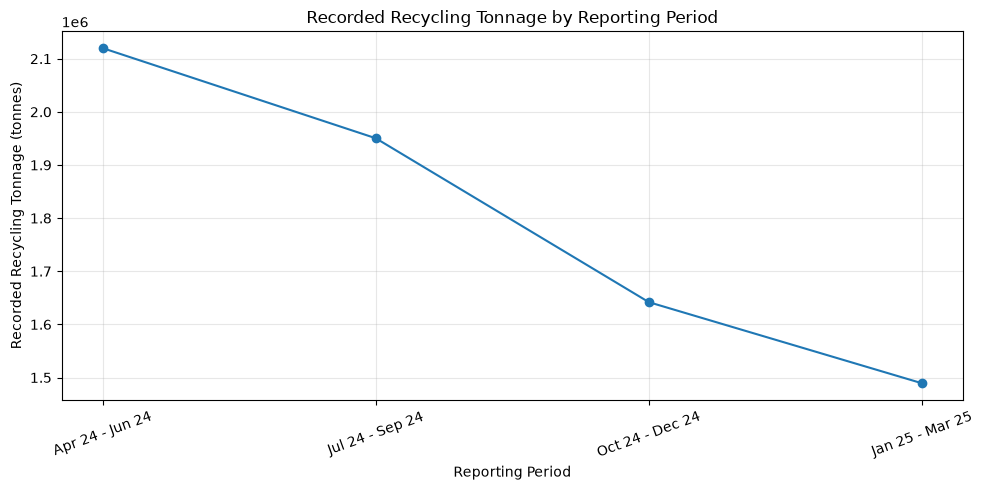

In [33]:

# Calculate the recorded recycling tonnage for each reporting period
period_tonnage = (
    recycling_df.groupby("Period")["Data_numeric"]
    .sum()
    .reindex([
        "Apr 24 - Jun 24",
        "Jul 24 - Sep 24",
        "Oct 24 - Dec 24",
        "Jan 25 - Mar 25"
    ])
)

# Create a line chart to show how the recorded totals changed
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(period_tonnage.index, period_tonnage.values, marker="o")

# Add a title and labels
plt.title("Recorded Recycling Tonnage by Reporting Period")
plt.xlabel("Reporting Period")
plt.ylabel("Recorded Recycling Tonnage (tonnes)")
plt.xticks(rotation=20)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#### Findings from the Recycling Trend Chart

The line chart shows that the recorded recycling tonnage decreased across the four reporting periods. April to June 2024 had the highest recorded total, at approximately 2.12 million tonnes, while January to March 2025 had the lowest, at approximately 1.49 million tonnes.

The figures show a downward trend in the recorded totals during the year. However, the chart does not explain why the totals decreased. Further investigation would be needed to understand the reasons for this change.

#### Comparing Local Authorities Across Reporting Periods

In this section, I will compare the recorded recycling tonnage of selected local authorities across the four reporting periods. This will help me see whether their recorded totals changed in similar or different ways during the year.

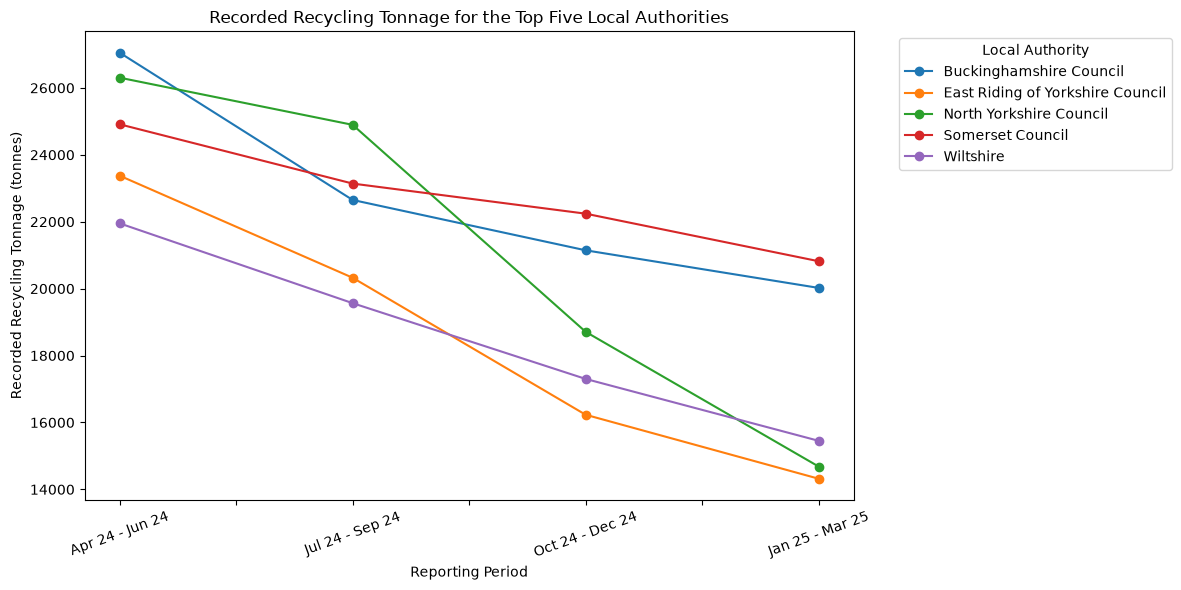

In [34]:

# Select the five local authorities with the highest recorded recycling totals
top_5_authority_names = top_10_authorities.sort_values(ascending=False).head(5).index

# Calculate recycling tonnage for each selected authority and reporting period
authority_period_tonnage = (
    recycling_df[recycling_df["Authority"].isin(top_5_authority_names)]
    .groupby(["Period", "Authority"])["Data_numeric"]
    .sum()
    .unstack()
    .reindex([
        "Apr 24 - Jun 24",
        "Jul 24 - Sep 24",
        "Oct 24 - Dec 24",
        "Jan 25 - Mar 25"
    ])
)

# Create a line chart to compare the authorities
import matplotlib.pyplot as plt

authority_period_tonnage.plot(figsize=(12, 6), marker="o")

# Add a title and labels
plt.title("Recorded Recycling Tonnage for the Top Five Local Authorities")
plt.xlabel("Reporting Period")
plt.ylabel("Recorded Recycling Tonnage (tonnes)")
plt.xticks(rotation=20)
plt.legend(title="Local Authority", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


#### Findings from the Local Authority Trend Chart

The line chart compares the recorded recycling tonnage of the five local authorities with the highest totals across the four reporting periods.

The chart helps me see how the recorded figures changed for each authority during the year. It also allows me to compare the patterns between the authorities.

However, the chart does not explain why the figures changed. Differences in population size, waste generation and collection arrangements may affect the totals, so further investigation would be needed before drawing conclusions about recycling performance.

#### Exploring Recycling Tonnage and Household Coverage

In this section, I will compare recorded recycling tonnage with the number of households reported as receiving a collection. This will help me explore whether authorities reporting higher recycling tonnage also report serving more households.

The comparison may help identify patterns, but it will not prove that serving more households causes higher recycling tonnage.

In [35]:

# Select records showing the number of households receiving a collection
household_df = kerbside_clean[
    kerbside_clean["ColText"] == "No. of households receiving a collection"
].copy()

# Display the number of records and unique authorities
print("Number of household records:", len(household_df))
print("Number of local authorities:", household_df["Authority"].nunique())

# Display a sample of the household records
display(
    household_df[
        ["Authority", "Period", "RowText", "Data", "Data_numeric"]
    ].head(10)
)


Number of household records: 6518
Number of local authorities: 294


,Authority,Period,RowText,Data,Data_numeric
9,Adur District Council,Apr 24 - Jun 24,Green garden waste only,6820,6820.0
12,Adur District Council,Apr 24 - Jun 24,WEEE - Small Domestic App,29133,29133.0
15,Adur District Council,Apr 24 - Jun 24,WEEE - Fridges & Freezers,29133,29133.0
18,Adur District Council,Apr 24 - Jun 24,Gas bottles,29133,29133.0
21,Adur District Council,Apr 24 - Jun 24,Co mingled materials,29133,29133.0
24,Adur District Council,Apr 24 - Jun 24,Other Scrap metal,29133,29133.0
60,Adur District Council,Jul 24 - Sep 24,Green garden waste only,6897,6897.0
63,Adur District Council,Jul 24 - Sep 24,WEEE - Large Domestic App,29133,29133.0
66,Adur District Council,Jul 24 - Sep 24,WEEE - Small Domestic App,29133,29133.0
69,Adur District Council,Jul 24 - Sep 24,WEEE - Fridges & Freezers,29133,29133.0


In [36]:

# Check the different household counts recorded for each reporting period
household_counts = (
    household_df.groupby(["Authority", "Period"])["Data_numeric"]
    .nunique()
)

# Show how many authority-period groups have one or more different counts
print("Number of authority-period groups:", len(household_counts))
print("\nNumber of groups with one unique household count:")
print((household_counts == 1).sum())

print("\nNumber of groups with multiple household counts:")
print((household_counts > 1).sum())

# Display examples where household counts differ
display(household_counts[household_counts > 1].head(10))


Number of authority-period groups: 1176

Number of groups with one unique household count:
120

Number of groups with multiple household counts:
1056


Authority                     Period         
Adur District Council         Apr 24 - Jun 24    2
                              Jan 25 - Mar 25    2
                              Jul 24 - Sep 24    2
                              Oct 24 - Dec 24    2
Amber Valley Borough Council  Apr 24 - Jun 24    3
                              Jan 25 - Mar 25    3
                              Jul 24 - Sep 24    2
                              Oct 24 - Dec 24    3
Arun District Council         Apr 24 - Jun 24    2
                              Jan 25 - Mar 25    3
Name: Data_numeric, dtype: int64

In [37]:

# Examine household collection figures for one authority and period
adur_households = household_df[
    (household_df["Authority"] == "Adur District Council") &
    (household_df["Period"] == "Apr 24 - Jun 24")
]

# Display the household figures for each material
display(
    adur_households[["RowText", "Data"]]
    .sort_values("RowText")
)


,RowText,Data
21,Co mingled materials,29133
18,Gas bottles,29133
9,Green garden waste only,6820
24,Other Scrap metal,29133
15,WEEE - Fridges & Freezers,29133
12,WEEE - Small Domestic App,29133


#### Findings from the Household Coverage Investigation

I examined the household collection figures and found that the number of households reported can differ between materials within the same local authority and reporting period.

For example, Adur District Council reported 29,133 households for several materials, while green garden waste only had 6,820 households for April to June 2024.

This means I cannot simply add the household figures together to calculate the total number of households served. I will treat this as a limitation of the data and focus my main comparisons on recorded recycling tonnage.

#### Exploring Co-mingled Recycling

In this section, I will examine the records showing whether recycling materials were collected together. I will count the Yes and No responses to understand how this information is recorded across local authorities and reporting periods.

These results will describe the recorded responses, but they will not measure the amount of recycling collected.

In [38]:

# Select records showing whether recycling materials were collected together
comingle_df = kerbside_clean[
    kerbside_clean["ColText"] == "Collected Co-mingled?"
].copy()

# Count the recorded Yes and No responses
comingle_counts = comingle_df["Data"].value_counts()

# Display the results
print("Recorded co-mingled collection responses:")
display(comingle_counts)


Recorded co-mingled collection responses:


Data
No     3113
Yes    1096
Name: count, dtype: int64

In [39]:

# Calculate the percentage of each recorded response
comingle_percentages = (
    comingle_df["Data"].value_counts(normalize=True) * 100
)

# Display the percentages to two decimal places
print("Percentage of recorded co-mingled collection responses:")
display(comingle_percentages.round(2))


Percentage of recorded co-mingled collection responses:


Data
No     73.96
Yes    26.04
Name: proportion, dtype: float64

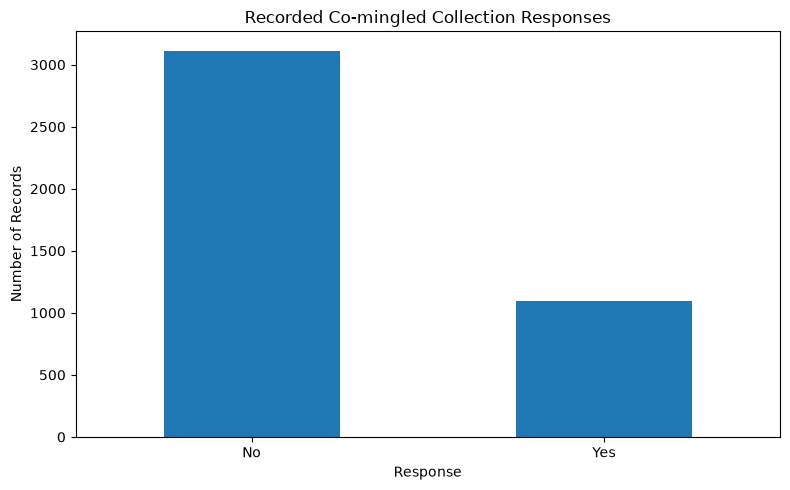

In [40]:

# Create a bar chart of the recorded co-mingled collection responses
import matplotlib.pyplot as plt

comingle_counts.plot(kind="bar", figsize=(8, 5))

# Add a title and labels
plt.title("Recorded Co-mingled Collection Responses")
plt.xlabel("Response")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


#### Findings from the Co-mingled Collection Chart

The bar chart shows that 3,113 recorded responses were No and 1,096 were Yes. This means 73.96% of the recorded responses were No, while 26.04% were Yes.

The results show that No was the more common response in this dataset. However, these percentages describe the recorded responses, not the percentage of all local authorities that use co-mingled collection. Some authorities may have several records because the data covers different materials and reporting periods.

## Summary of Exploratory Data Analysis

In this project, I explored waste collection data for England for the 2024–2025 reporting year. I examined recorded recycling tonnage across reporting periods, compared totals between local authorities, investigated the materials with the highest recorded tonnage, and reviewed rejected recycling and co-mingled collection responses.

My analysis identified differences in recorded recycling tonnage across periods and local authorities. I also found that household counts vary by material, which limits how they can be compared. These findings describe the available records and do not, on their own, explain why the differences occurred.

## Preparing Data for the Dashboard

In this section, I will prepare the cleaned recycling tonnage data for use in my dashboard. I will keep the relevant columns, check the data and save the cleaned data to a CSV file.

This will make it easier to use the same prepared data in my data app and reproduce my analysis.

In [41]:

# Keep only the columns needed for the recycling dashboard
dashboard_df = recycling_df[
    ["Authority", "Period", "RowText", "Data_numeric"]
].copy()

# Rename the numeric column to make its purpose clearer
dashboard_df = dashboard_df.rename(
    columns={"Data_numeric": "Recycling_Tonnage"}
)

# Remove records without a numeric recycling tonnage
dashboard_df = dashboard_df.dropna(subset=["Recycling_Tonnage"])

# Check the cleaned dashboard data
print("Dashboard dataset shape:", dashboard_df.shape)
print("\nMissing values in each column:")
display(dashboard_df.isnull().sum())

# Display the first five rows
display(dashboard_df.head())


Dashboard dataset shape: (6330, 4)

Missing values in each column:


Authority            0
Period               0
RowText              0
Recycling_Tonnage    0
dtype: int64

,Authority,Period,RowText,Recycling_Tonnage
8,Adur District Council,Apr 24 - Jun 24,Green garden waste only,1160.23
11,Adur District Council,Apr 24 - Jun 24,WEEE - Small Domestic App,6.21
14,Adur District Council,Apr 24 - Jun 24,WEEE - Fridges & Freezers,5.00
17,Adur District Council,Apr 24 - Jun 24,Gas bottles,0.28
20,Adur District Council,Apr 24 - Jun 24,Co mingled materials,1055.76


In [42]:

# Save the cleaned dashboard dataset as a CSV file
output_file = "cleaned_recycling_dashboard.csv"

dashboard_df.to_csv(output_file, index=False)

print(f"Cleaned dashboard data saved to: {output_file}")


Cleaned dashboard data saved to: cleaned_recycling_dashboard.csv


In [43]:

# Check the current working folder and confirm the CSV file exists
import os

print("Current working folder:")
print(os.getcwd())

print("\nDoes the cleaned CSV file exist?")
print(os.path.exists("cleaned_recycling_dashboard.csv"))


Current working folder:
c:\Users\yetun\Desktop\Code Institute Registration Documents for Level 3 Data Analysis with AI\UNIT 3 ASSESSMENT FINAL PROJECT

Does the cleaned CSV file exist?
True


## Building the Interactive Dashboard

In this section, I will build an interactive dashboard using Streamlit. The dashboard will use the cleaned recycling data prepared earlier in this project.

The dashboard will allow users to filter the data by reporting period and local authority. It will display key figures and charts to help users explore recorded recycling tonnage across reporting periods and materials.

The aim is to present the findings clearly and make the data easier to explore. I will also test the dashboard to check that its filters, figures and charts work as expected.

#### Dashboard Testing

I tested my Streamlit dashboard in Chrome to check that it displayed correctly. I confirmed that the dashboard showed the title, key figures, a bar chart and a pie chart.

I also tested the reporting-period filter by selecting one reporting period. The recorded recycling tonnage changed from 7,201,391 tonnes to 2,120,028 tonnes for April to June 2024. This confirmed that the filter was working correctly.

I restored the dashboard to its default view and confirmed that all four reporting periods and 294 local authorities were included again.

The dashboard uses the cleaned recycling dataset prepared during my analysis. The figures describe recorded recycling tonnage and should not be treated as a complete measure of recycling performance.